## Контрольная работа 5. Вариант 2

Нельзя пользоваться готовыми высокоуровневыми решателями: `solve_ivp`, `solve_bvp`, `NDSolve`, `FEniCS` и аналогами.
В задаче 2 разрешается использовать `scipy.optimize.root_scalar` для подбора параметра начального наклона.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar
from mpl_toolkits.mplot3d import Axes3D
import warnings

__Задача 1.__

Решить систему дифференциальных уравнений на интервале $[0,10]$

$$
\begin{aligned}
& u'=998u+1998v, \\
& v'=-999u-1999v
\end{aligned}
$$

с начальными значениями $u(0)=v(0)=1$ явным и неявным методами Эйлера. Сравните полученные результаты и прокомментируйте влияние жёсткости задачи.


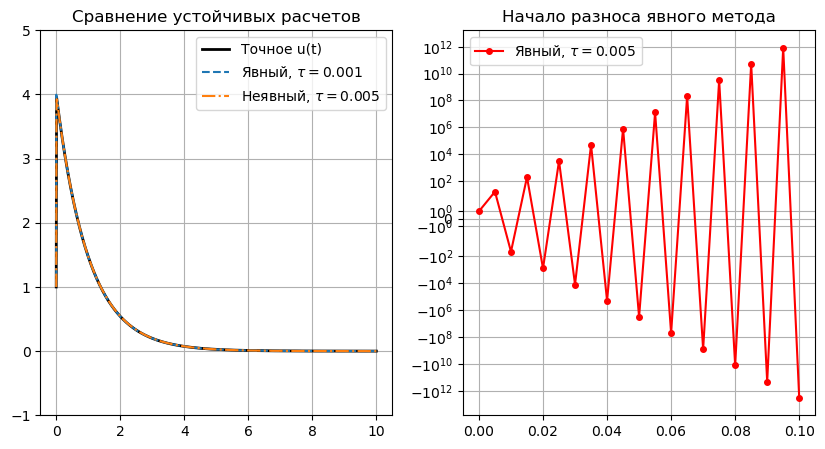

In [22]:
# Точное решение для сравнения

def exact_solution_ode(t):
    u = 4 * np.exp(-t) - 3 * np.exp(-1000 * t)
    v = -2 * np.exp(-t) + 3 * np.exp(-1000 * t)
    return u, v

# Явный метод Эйлера
def explicit_euler(A, y0, t_span, tau):
    t = np.arange(t_span[0], t_span[1] + tau, tau)
    y = np.zeros((len(t), len(y0)))
    y[0] = y0
    
    for i in range(len(t) - 1):
        y[i+1] = y[i] + tau * (A @ y[i])
        
    return t, y

# Неявный метод Эйлера
def implicit_euler(A, y0, t_span, tau):
    t = np.arange(t_span[0], t_span[1] + tau, tau)
    y = np.zeros((len(t), len(y0)))
    y[0] = y0
    
    I = np.eye(len(y0))
    M = I - tau * A
    
    for i in range(len(t) - 1):
        y[i+1] = np.linalg.solve(M, y[i])
        
    return t, y

# Инициализация параметров
A = np.array([[998, 1998],[-999, -1999]])
y0 = np.array([1, 1])
t_span = (0, 10)

# 1. Устойчивое решение явным методом. Шаг устойчив, но для быстрого слоя он еще довольно грубый.
tau_stable = 0.001
t_ex_s, y_ex_s = explicit_euler(A, y0, t_span, tau_stable)

# 2. Решение с неустойчивым для явного метода шагом
tau_unstable = 0.005

# Игнорируем предупреждения о переполнении для демонстрации "взрыва"
with np.errstate(over='ignore', invalid='ignore'):
    t_ex_u, y_ex_u = explicit_euler(A, y0, t_span, tau_unstable)

t_im_u, y_im_u = implicit_euler(A, y0, t_span, tau_unstable)

# 3. Отрисовка графиков
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

t_exact = np.linspace(0, 10, 1000)
u_exact, v_exact = exact_solution_ode(t_exact)

axs[0].plot(t_exact, u_exact, 'k-', linewidth=2, label='Точное u(t)')
axs[0].plot(t_ex_s, y_ex_s[:, 0], '--', label=fr'Явный, $\tau={tau_stable:g}$')
axs[0].plot(t_im_u, y_im_u[:, 0], '-.', label=fr'Неявный, $\tau={tau_unstable:g}$')
axs[0].set_title('Сравнение устойчивых расчетов')
axs[0].set_ylim(-1, 5)
axs[0].legend()
axs[0].grid()

# Отрисуем точки до t = 0.1, чтобы увидеть раскачку
N_points_to_show = 21
axs[1].plot(t_ex_u[:N_points_to_show], y_ex_u[:N_points_to_show, 0], 'r-o', markersize=4, label=fr'Явный, $\tau={tau_unstable:g}$')
axs[1].set_title('Начало разноса явного метода')
axs[1].set_yscale('symlog') # Логарифмический масштаб
axs[1].legend()
axs[1].grid()

plt.show()


**1. Спектр матрицы и показатель жёсткости**
Запишем систему в матричном виде $\mathbf{u}' = A \mathbf{u}$, где матрица Якоби:
$$ A = \begin{pmatrix} 998 & 1998 \\ -999 & -1999 \end{pmatrix} $$
Найдем её собственные значения из характеристического уравнения $\det(A - \lambda I) = 0$:
$$ (998-\lambda)(-1999-\lambda) - 1998 \cdot (-999) = 0 \implies \lambda^2 + 1001\lambda + 1000 = 0 $$
Корни: $\lambda_1 = -1$ и $\lambda_2 = -1000$.
Показатель жёсткости системы равен отношению максимального по модулю собственного значения к минимальному: 
$$ S = \frac{|\lambda_2|}{|\lambda_1|} = \frac{1000}{1} = 1000 \gg 1 $$
Поскольку $S$ велико, а оба собственных значения отрицательны, **система является сильно жёсткой**. В ней одновременно присутствуют процессы с сильно различающимися скоростями: быстро затухающая компонента ($e^{-1000t}$) и медленно меняющаяся ($e^{-t}$).

**2. Поведение явного метода Эйлера (влияние барьера устойчивости)**
Функция устойчивости явного метода Эйлера: $R(z) = 1 + z$, где $z = \lambda \tau$. 
Для того чтобы метод не «пошел в разнос» (был устойчив), необходимо выполнение условия $|1 + \lambda \tau| \le 1$. 
Для самого жесткого собственного значения $\lambda_2 = -1000$ получаем ограничение на шаг по времени:
$$ |1 - 1000\tau| \le 1 \implies 1000\tau \le 2 \implies \tau \le 0.002 $$
Если выбрать шаг хотя бы немного больше (например, $\tau = 0.005$), множитель перехода становится по модулю больше единицы ($|1 - 5| = 4$). Из-за этого ошибка на каждом шаге умножается на $-4$, решение начинает дико осциллировать с растущей амплитудой, и происходит **взрыв схемы** (переполнение). Таким образом, явный метод заставляет нас брать неадекватно малый шаг не для достижения точности, а исключительно ради сохранения устойчивости.
В расчете выше $\tau=0.001$ уже удовлетворяет этому ограничению, но начальный быстрый слой все равно описывается грубо; для высокой точности на всем отрезке нужен еще меньший шаг.

**3. Поведение неявного метода Эйлера (А-устойчивость)**
Функция устойчивости неявного метода: $R(z) = \frac{1}{1 - z}$. 
Для любого $\lambda < 0$ и $\tau > 0$ знаменатель $|1 - \lambda \tau| > 1$, а значит $|R(z)| < 1$. 
Метод является **А-устойчивым** (и L-устойчивым). Он стабилен при *абсолютно любом* шаге интегрирования. Матрица перехода корректно и моментально «гасит» быструю компоненту решения, позволяя нам выбрать размер шага $\tau$ исходя только из требований к точности медленной компоненты решения, экономя колоссальное количество вычислительных ресурсов.

**Общий вывод:**
Для жёстких систем использование явных методов приводит к вычислительной неэффективности (необходимости делать миллионы микроскопических шагов) или неверным результатам из-за потери устойчивости. Для таких задач необходимо применять неявные схемы, чья область абсолютной устойчивости включает в себя левую полуплоскость комплексной плоскости.

__Задача 2.__

Реализовать алгоритм метода стрельбы для вычисления решения следующей нелинейной краевой задачи:

$$
\left\{
\begin{array}{c}
y''-x^3\sqrt{y}=0, \quad 0 \leq x \leq 1, \\
y(0)=0, \quad y(1)=2.
\end{array}
\right.
$$


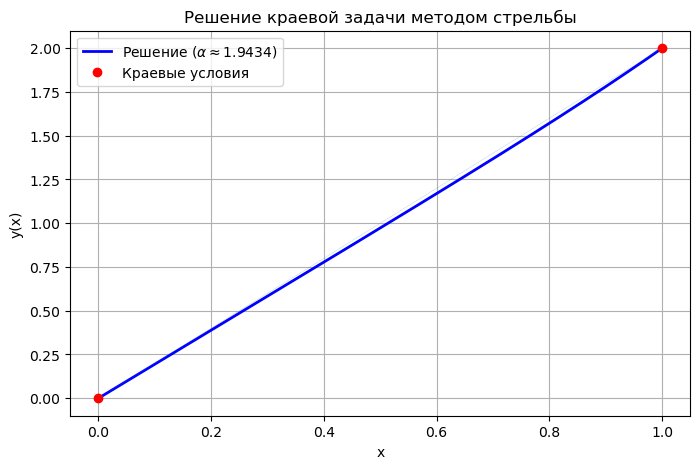

In [23]:
# Система ДУ 1-го порядка
def f(x, Y):
    y1, y2 = Y
    dy1 = y2
    dy2 = (x**3) * np.sqrt(np.maximum(0, y1))
    return np.array([dy1, dy2])

# Метод Рунге-Кутты (RK4)
def rk4_solve(alpha, x_span, N):
    x0, x_end = x_span
    h = (x_end - x0) / N
    x = np.linspace(x0, x_end, N + 1)
    Y = np.zeros((N + 1, 2))
    
    Y[0] = [0.0, alpha]
    
    for i in range(N):
        k1 = f(x[i], Y[i])
        k2 = f(x[i] + h/2, Y[i] + h/2 * k1)
        k3 = f(x[i] + h/2, Y[i] + h/2 * k2)
        k4 = f(x[i] + h, Y[i] + h * k3)
        Y[i+1] = Y[i] + (h/6) * (k1 + 2*k2 + 2*k3 + k4)
        
    return x, Y

# Функция невязки
def residual(alpha):
    x, Y = rk4_solve(alpha, (0, 1), 200)
    return Y[-1, 0] - 2.0

# Подбор параметра
res = root_scalar(residual, bracket=[0, 5], method='bisect')
alpha_opt = res.root

# Итоговое решение
x_opt, Y_opt = rk4_solve(alpha_opt, (0, 1), 200)

# Отрисовка
plt.figure(figsize=(8, 5))
plt.plot(x_opt, Y_opt[:, 0], 'b-', linewidth=2, label=f'Решение ($\\alpha \\approx {alpha_opt:.4f}$)')
plt.plot([0, 1], [0, 2], 'ro', markersize=6, label='Краевые условия')
plt.plot([0, 1], [0, 2], linewidth=0.1)
plt.title("Решение краевой задачи методом стрельбы")
plt.xlabel("x")
plt.ylabel("y(x)")
plt.grid(True)
plt.legend()
plt.show()

__Задача 3.__

Решите следующее уравнение в частных производных конечно-разностной схемой. Постройте визуализацию решения и исследуйте сходимость на сгущающихся сетках, используя точное решение.

$$
\begin{aligned}
& u_t=u_{xx}+2e^{-2t}(1-x+x^2), \quad 0 \leq x \leq 1, \quad 0<t\leq 1, \\
& u(0,t)=0, \quad u(1,t)=0, \quad u(x,0)=x(1-x).
\end{aligned}
$$

Точное решение:

$$
u(x,t)=e^{-2t}x(1-x).
$$


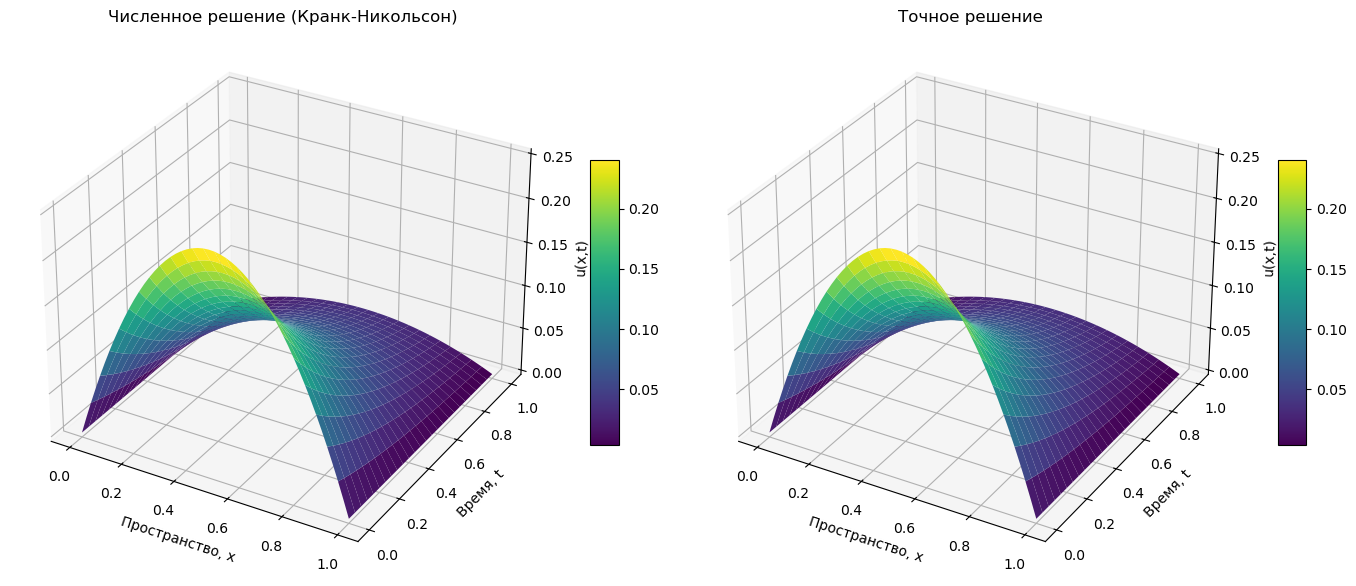

   N=M    max error    order
    10  8.168957e-04      ---
    20  1.952007e-04    2.065
    40  4.850915e-05    2.009
    80  1.210653e-05    2.002
   160  3.026583e-06    2.000


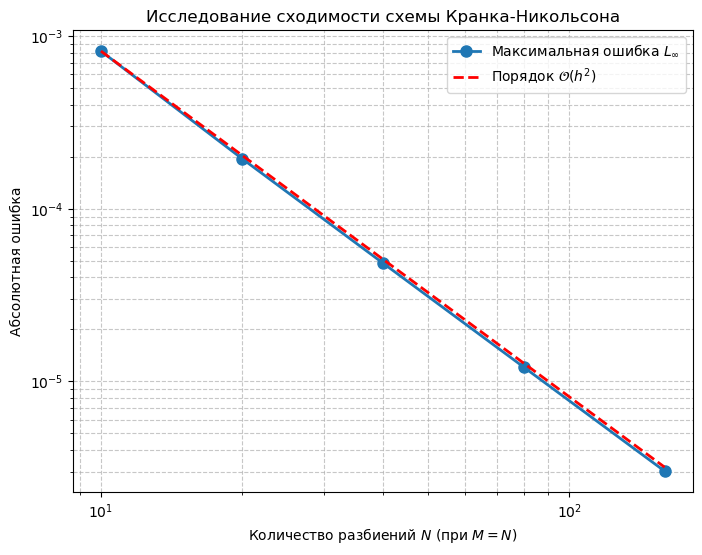

In [24]:
# Определение исходных функций
def exact_solution_pde(x, t):
    return np.exp(-2 * t) * x * (1 - x)

def f_source(x, t):
    return 2 * np.exp(-2 * t) * (1 - x + x**2)

# Реализация схемы Кранка - Николсона
def solve_crank_nicolson(N, M):
    h = 1.0 / N
    tau = 1.0 / M
    x = np.linspace(0, 1, N + 1)
    t = np.linspace(0, 1, M + 1)
    
    # Матрица для хранения решения
    u = np.zeros((M + 1, N + 1))
    
    # Начальное условие
    u[0, :] = x * (1 - x)
    
    gamma = tau / (2 * h**2)
    
    # Формируем трехдиагональную матрицу A для левой части
    A = np.zeros((N - 1, N - 1))
    np.fill_diagonal(A, 1 + 2 * gamma)
    np.fill_diagonal(A[1:], -gamma)
    np.fill_diagonal(A[:, 1:], -gamma)
    
    # Итерации по времени
    for n in range(M):
        t_half = t[n] + tau / 2
        f = f_source(x[1:-1], t_half)
        
        # Формируем вектор правой части b
        b = gamma * u[n, :-2] + (1 - 2 * gamma) * u[n, 1:-1] + gamma * u[n, 2:] + tau * f
        
        # Граничные условия равны 0, поэтому края вектора b не модифицируются
        # Решаем СЛАУ A * u^{n+1} = b
        u[n+1, 1:-1] = np.linalg.solve(A, b)
        
    return x, t, u

# 1. Визуализация численного и точного решения
N, M = 50, 50
x, t, u_num = solve_crank_nicolson(N, M)
X, T = np.meshgrid(x, t)
U_ex = exact_solution_pde(X, T)

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection='3d')
surf1 = ax1.plot_surface(X, T, u_num, cmap='viridis', edgecolor='none')
ax1.set_title('Численное решение (Кранк-Никольсон)')
ax1.set_xlabel('Пространство, x')
ax1.set_ylabel('Время, t')
ax1.set_zlabel('u(x,t)')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

ax2 = fig.add_subplot(122, projection='3d')
surf2 = ax2.plot_surface(X, T, U_ex, cmap='viridis', edgecolor='none')
ax2.set_title('Точное решение')
ax2.set_xlabel('Пространство, x')
ax2.set_ylabel('Время, t')
ax2.set_zlabel('u(x,t)')
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

plt.tight_layout()
plt.show()

# 2. Исследование сходимости
grids = [10, 20, 40, 80, 160]
errors = []

for N_grid in grids:
    # Чтобы ошибка убывала как O(h^2), берем M = N, тогда tau ~ h
    # При O(tau^2 + h^2) общая ошибка составит O(h^2)
    M_grid = N_grid
    x_g, t_g, u_g = solve_crank_nicolson(N_grid, M_grid)
    
    X_g, T_g = np.meshgrid(x_g, t_g)
    U_exact_g = exact_solution_pde(X_g, T_g)
    
    # Считаем максимальную абсолютную ошибку по всей сетке (норма L_inf)
    error = np.max(np.abs(u_g - U_exact_g))
    errors.append(error)

orders = [np.nan]
for prev_error, error in zip(errors[:-1], errors[1:]):
    orders.append(np.log(prev_error / error) / np.log(2))

print('   N=M    max error    order')
for N_grid, error, order in zip(grids, errors, orders):
    order_text = '---' if np.isnan(order) else f'{order:.3f}'
    print(f'{N_grid:6d}  {error:.6e}  {order_text:>7}')

plt.figure(figsize=(8, 6))
plt.loglog(grids, errors, 'o-', linewidth=2, markersize=8, label=r'Максимальная ошибка $L_\infty$')

# Добавляем идеальную прямую второго порядка сходимости O(h^2) для сравнения
base_err = errors[0]
plt.loglog(grids, [base_err * (grids[0]/n)**2 for n in grids], 'r--', linewidth=2, label=r'Порядок $\mathcal{O}(h^2)$')

plt.xlabel('Количество разбиений $N$ (при $M = N$)')
plt.ylabel('Абсолютная ошибка')
plt.title('Исследование сходимости схемы Кранка-Никольсона')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.show()
